In [6]:
import pandas as pd
from pathlib import Path

In [7]:
data_path = Path("../data/processed")

orders = pd.read_csv(data_path / "orders.csv", parse_dates=["order_date"])
items = pd.read_csv(data_path / "order_items.csv")

In [8]:
print(orders[["order_id", "customer_id", "order_date", "order_status"]].head(3))
print(items[["order_id", "quantity", "unit_price"]].head(3))

     order_id customer_id order_date order_status
0  ORD1000000  CUST103868 2025-08-16       Failed
1  ORD1000001  CUST118472 2023-02-11    Delivered
2  ORD1000002  CUST120793 2024-12-14    Delivered
     order_id  quantity  unit_price
0  ORD1000000         4       150.0
1  ORD1000000         1      1150.0
2  ORD1000000         2       960.0


In [9]:
delivered = orders.loc[orders["order_status"].eq("Delivered")]

sales = items.merge(
    delivered[["order_id", "customer_id", "order_date"]],
    on="order_id"
)

sales["amount"] = sales["quantity"] * sales["unit_price"]

In [10]:
snapshot = sales["order_date"].max() + pd.Timedelta(days=1)

rfm = sales.groupby("customer_id").agg(
    Recency=("order_date", lambda x: (snapshot - x.max()).days),
    Frequency=("order_id", "nunique"),
    Monetary=("amount", "sum")
).round(2)

rfm.head()

,Recency,Frequency,Monetary
customer_id,,,
CUST100000,951,2,5140.0
CUST100001,588,7,386370.0
CUST100002,171,9,114930.0
CUST100003,13,1,3720.0
CUST100004,792,2,63740.0


In [11]:
rfm.describe().round(1)

,Recency,Frequency,Monetary
count,21849.0,21849.0,21849.0
mean,376.7,3.7,104325.5
std,323.3,2.8,130223.9
min,1.0,1.0,50.0
25%,66.0,2.0,16760.0
50%,305.0,3.0,53120.0
75%,661.0,5.0,144350.0
max,1085.0,22.0,1257340.0


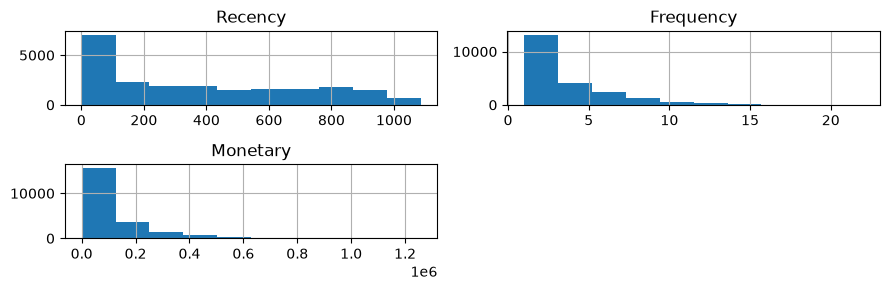

In [12]:
import matplotlib.pyplot as plt
rfm[["Recency", "Frequency", "Monetary"]].hist(figsize=(9, 3))
plt.tight_layout()
plt.show()

In [13]:
rfm.to_csv("../data/processed/customer_rfm.csv")

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X = StandardScaler().fit_transform(rfm)
rfm["Segment"] = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X)

rfm.groupby("Segment")[["Recency", "Frequency", "Monetary"]].mean().round(1)

,Recency,Frequency,Monetary
Segment,,,
0,759.4,2.5,56381.6
1,374.3,9.6,450052.4
2,247.3,6.4,186184.4
3,156.7,2.4,45055.8


In [15]:
import sys
print(sys.executable)
print(sys.version)

d:\DataScience\Projects\AI E-Commerce Customer Intelligence & Recommendation System\.venv\Scripts\python.exe
3.13.16 (tags/v3.13.16:cbc944f, Sep 30 2026, 19:17:50) [MSC v.1944 64 bit (AMD64)]


In [16]:
rfm.groupby("Segment").agg(
    Customers=("Segment", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean")
).round(1)

,Customers,Recency,Frequency,Monetary
Segment,,,,
0,6781,759.4,2.5,56381.6
1,1491,374.3,9.6,450052.4
2,4353,247.3,6.4,186184.4
3,9224,156.7,2.4,45055.8


In [17]:
rfm.to_csv("../data/processed/customer_segments.csv")
print("Customer segments saved successfully!")

Customer segments saved successfully!
